<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="300" alt="Skills Network Logo">
    </a>
</p>


# Test Environment for Generative AI classroom labs

This lab provides a test environment for the codes generated using the Generative AI classroom.

Follow the instructions below to set up this environment for further use.


# Setup


### Install required libraries

In case of a requirement of installing certain python libraries for use in your task, you may do so as shown below.


In [1]:
%pip install seaborn
import piplite

await piplite.install(['nbformat', 'plotly'])

### Dataset URL from the GenAI lab
Use the URL provided in the GenAI lab in the cell below. 


In [2]:
URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMSkillsNetwork-AI0271EN-SkillsNetwork/labs/v1/m3/data/used_car_price_analysis.csv"

### Downloading the dataset

Execute the following code to download the dataset in to the interface.

> Please note that this step is essential in JupyterLite. If you are using a downloaded version of this notebook and running it on JupyterLabs, then you can skip this step and directly use the URL in pandas.read_csv() function to read the dataset as a dataframe


In [3]:
from pyodide.http import pyfetch

async def download(url, filename):
    response = await pyfetch(url)
    if response.status == 200:
        with open(filename, "wb") as f:
            f.write(await response.bytes())

path = URL

await download(path, "dataset.csv")
file_name  = "dataset.csv"

---


# Test Environment


In [ ]:
# Code generated by prompting GPT-5.4 Nano

In [4]:
# Importing the dataset
import pandas as pd

path = "dataset.csv"
df = pd.read_csv(path)
print(df.head())


<ipython-input-4-ad381b03c9fa>:2: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


     model  year transmission  mileage fuelType    tax   mpg  engineSize  \
0   Fiesta  2017    Automatic    15944   Petrol  150.0  57.7         1.0   
1    Focus  2018       Manual     9083   Petrol  150.0  57.7         1.0   
2    Focus  2017       Manual    12456   Petrol  150.0  57.7         1.0   
3   Fiesta  2019       Manual    10460   Petrol  145.0  40.3         1.5   
4   Fiesta  2019    Automatic     1482   Petrol  145.0  48.7         1.0   

   price  
0  12000  
1  14000  
2  13000  
3  17500  
4  16500  


In [5]:
#Handling missing and duplicate values

cols_with_na = df.columns[df.isna().any()].tolist()

for c in cols_with_na:
    df[c] = df[c].fillna(df[c].mean())

df = df.drop_duplicates().reset_index(drop=True)

print(cols_with_na)
print(df.head())

['tax']
     model  year transmission  mileage fuelType    tax   mpg  engineSize  \
0   Fiesta  2017    Automatic    15944   Petrol  150.0  57.7         1.0   
1    Focus  2018       Manual     9083   Petrol  150.0  57.7         1.0   
2    Focus  2017       Manual    12456   Petrol  150.0  57.7         1.0   
3   Fiesta  2019       Manual    10460   Petrol  145.0  40.3         1.5   
4   Fiesta  2019    Automatic     1482   Petrol  145.0  48.7         1.0   

   price  
0  12000  
1  14000  
2  13000  
3  17500  
4  16500  


In [6]:
# Identify the 5 attributes that have the highest correlation with the price parameter.

target = "price"
corr = df.corr(numeric_only=True)[target].drop(target)
top5 = corr.abs().sort_values(ascending=False).head(5)
print(top5.index.tolist())
print(top5)

['year', 'mileage', 'engineSize', 'tax', 'mpg']
year          0.635715
mileage       0.530483
engineSize    0.411451
tax           0.405970
mpg           0.346263
Name: price, dtype: float64


In [7]:
# Count the number of cars under each unique value of fuelType attribute.

attr = "fuelType"
counts = df[attr].value_counts()
print(counts)

fuelType
Petrol      12081
Diesel       5706
Hybrid         22
Electric        2
Other           1
Name: count, dtype: int64


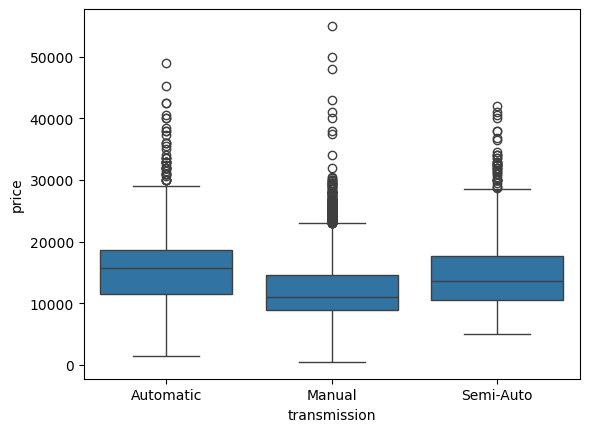

In [8]:
# Create a Seaborn Box plot to determine whether cars with automatic, manual or semi-auto type of transmission have more price outliers.

import seaborn as sns
import matplotlib.pyplot as plt

source_col = "transmission"
target_col = "price"

sns.boxplot(data=df, x=source_col, y=target_col)
plt.show()



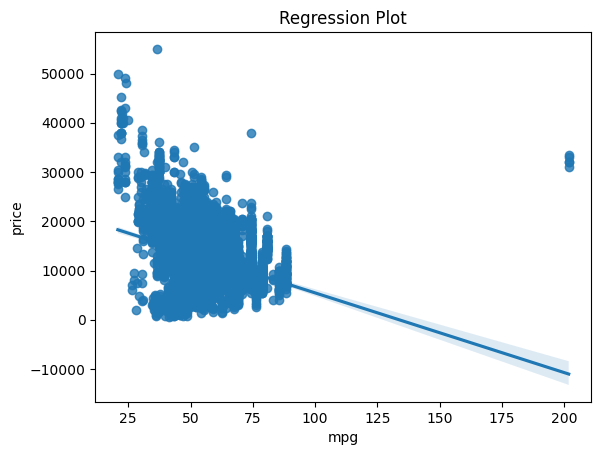

In [9]:
# Regression plot between mpg parameter and the price to determine the correlation type between the two.

source_attribute = "mpg"
target_attribute = "price"

sns.regplot(data=df, x=source_attribute, y=target_attribute)
plt.xlabel(source_attribute)
plt.ylabel(target_attribute)
plt.title("Regression Plot")
plt.show()

In [10]:
# Fit a linear regression model to predict the price using the feature mpg. Then calculate the R^2 and MSE values for the model.

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

X = df[["mpg"]]
y = df["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_test)

r2 = r2_score(y_test, predictions)
mse = mean_squared_error(y_test, predictions)

print("R²:", r2)
print("MSE:", mse)


R²: 0.1504343741072478
MSE: 19049855.140110757


In [11]:
# Fit a linear regression model to predict the price using the top 5 features. Calculate the R^2 and MSE values for this model.

source_attributes = ["year", "mileage", "tax", "mpg", "engineSize"]
target_attribute = "price"

X = df[source_attributes]
y = df[target_attribute]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

r2 = r2_score(y_test, predictions)
mse = mean_squared_error(y_test, predictions)

print("R²:", r2)
print("MSE:", mse)


R²: 0.6917125923771564
MSE: 6912744.910746688


In [13]:
# Create a pipeline model object that uses standard scalar, second degree polynomial features and a linear regression model. Calculate the R^2 value and the MSE value for this model.

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures

source_attributes = ["year", "mileage", "tax", "mpg", "engineSize"]
target_attribute = "price"

X = df[source_attributes]
y = df[target_attribute]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = Pipeline([
    ("scaler", StandardScaler()),
    ("polynomial", PolynomialFeatures(degree=2)),
    ("regression", LinearRegression())
])

model.fit(X_train, y_train)

predictions = model.predict(X_test)

r2 = r2_score(y_test, predictions)
mse = mean_squared_error(y_test, predictions)

print("R²:", r2)
print("MSE:", mse)


R²: 0.12122807147174242
MSE: 19704749.61491952


In [14]:
# Create and fit a Ridge regression object using the training data, set the regularization parameter to 0.1, and calculate the R^2 using the test data.

from sklearn.linear_model import Ridge

source_attributes = ["year", "mileage", "tax", "mpg", "engineSize"]
target_attribute = "price"

X = df[source_attributes]
y = df[target_attribute]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

model = Ridge(alpha=0.1)
model.fit(X_train, y_train)

predictions = model.predict(X_test)

mse = mean_squared_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print("MSE:", mse)
print("R²:", r2)

MSE: 6912725.801054926
R²: 0.6917134446113138


In [15]:
# Perform a second order polynomial transform on both the training data and testing data created for the above.

source_attributes = ["year", "mileage", "tax", "mpg", "engineSize"]
target_attribute = "price"

X = df[source_attributes]
y = df[target_attribute]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

polynomial = PolynomialFeatures(degree=2, include_bias=False)

X_train_poly = polynomial.fit_transform(X_train)
X_test_poly = polynomial.transform(X_test)

model = Ridge(alpha=0.1)
model.fit(X_train_poly, y_train)

predictions = model.predict(X_test_poly)

mse = mean_squared_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print("MSE:", mse)
print("R²:", r2)


/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:204: LinAlgWarning: Ill-conditioned matrix (rcond=2.1777e-24): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


MSE: 7326174.5165419085
R²: 0.673274888823681


In [17]:
# Perform a Grid Search on ridge regression for a set of values of alpha {0.01, 0.1, 1, 10, 100} with 4-fold cross validation to find the optimum value of alpha to be used for the prediction model.

from sklearn.model_selection import GridSearchCV

source_attributes = ["year", "mileage", "tax", "mpg", "engineSize"]
target_attribute = "price"

X = df[source_attributes]
y = df[target_attribute]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

polynomial = PolynomialFeatures(degree=2, include_bias=False)

X_train_poly = polynomial.fit_transform(X_train)
X_test_poly = polynomial.transform(X_test)

ridge = Ridge()
parameters = {"alpha": [0.01, 0.1, 1, 10, 100]}

grid_search = GridSearchCV(
    ridge,
    parameters,
    cv=4,
    scoring="neg_mean_squared_error"
)

grid_search.fit(X_train_poly, y_train)

predictions = grid_search.predict(X_test_poly)

mse = mean_squared_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print("Best alpha:", grid_search.best_params_["alpha"])
print("MSE:", mse)
print("R²:", r2)


/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:204: LinAlgWarning: Ill-conditioned matrix (rcond=3.0567e-25): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:204: LinAlgWarning: Ill-conditioned matrix (rcond=2.98143e-25): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:204: LinAlgWarning: Ill-conditioned matrix (rcond=3.10209e-25): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:204: LinAlgWarning: Ill-conditioned matrix (rcond=2.85743e-25): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:204: LinAlgWarning: Ill-conditioned matrix (rcond=2.9414e-24): resul

Best alpha: 0.01
MSE: 13840985.11755802
R²: 0.38273414165699104


## Authors


[Abhishek Gagneja](https://www.linkedin.com/in/abhishek-gagneja-23051987/)


## Change Log


|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
|-|-|-|-|
|2023-12-10|0.1|Abhishek Gagneja|Initial Draft created|


Copyright © 2023 IBM Corporation. All rights reserved.
